# Background: what compression is, and why Huffman and LZW were needed

**INF605 Digital Image Processing, Group 8.** Paper 8: Huffman coding (1952) and LZW coding (1984).

This notebook is the background part of our project. It answers the first two points of the Week 13 talk: *what problem is being solved*, and *which ideas from the course and the book the methods build on*. Each section has a short explanation, then a small experiment that shows the idea on real numbers.

**Sources.** R. C. Gonzalez and R. E. Woods, *Digital Image Processing*, 4th ed., Chapter 8, Section 8.1 (we call it "the book"); C. E. Shannon, "A mathematical theory of communication," *Bell System Technical Journal*, 1948; D. A. Huffman, *Proc. IRE*, 1952.

**Map of this notebook**

1. Data, compression ratio and redundancy
2. Information and entropy
3. Where the redundancy in an image comes from
4. Codes, average length and Shannon's first theorem
5. Simple methods that came before, and why they are not enough
6. How this leads to Huffman and LZW

In [1]:
import os, math
from itertools import product
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 110

IMAGE_DIR = next(p for p in ("../images", "images") if os.path.isdir(p))
FILES = {
    "moon":           "5.1.09.tiff",
    "desert":         "7.1.10.tiff",
    "mandrill":       "4.2.03.tiff",       # colour file, converted to gray below
    "texture mosaic": "texmos1.p512.tiff",
}

def load_gray(path):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img          # 8-bit gray

images = {name: load_gray(os.path.join(IMAGE_DIR, f)) for name, f in FILES.items()}
{name: im.shape for name, im in images.items()}

{'moon': (256, 256),
 'desert': (512, 512),
 'mandrill': (512, 512),
 'texture mosaic': (512, 512)}

## 1. Data, compression ratio and redundancy

**Data** is the actual stream of bits we store. **Information** is what those bits tell us. The same information can be written with more or fewer bits, and the extra bits that add nothing are called **redundant**.

If one representation uses $b$ bits and another uses $b'$ bits for the same information, the book defines (Eq. 8-2 and 8-1)

$$C = \frac{b}{b'} \qquad\qquad R = 1 - \frac{1}{C}$$

$C$ is the **compression ratio** ($C = 4$ means "four times smaller"). $R$ is the **relative redundancy**: the share of the bigger representation that was not needed. $C = 10$ gives $R = 0.9$, so 90 % of the data was redundant.

Below we reproduce the book's own Example 8.1: an image with four gray values, stored with a fixed 8-bit code and with a variable-length code that gives short code words to common values.

In [2]:
# Book Example 8.1
p      = {87: 0.25, 128: 0.47, 186: 0.25, 255: 0.03}   # probability of each gray value
length = {87: 2,    128: 1,    186: 3,    255: 3}      # code words 01, 1, 000, 001

L_avg = sum(p[k] * length[k] for k in p)               # average bits per pixel
C = 8 / L_avg
R = 1 - 1 / C
print(f"L_avg = {L_avg:.2f} bits/pixel, C = {C:.2f}, R = {R:.3f}   (book: 1.81, 4.42, 0.774)")

L_avg = 1.81 bits/pixel, C = 4.42, R = 0.774   (book: 1.81, 4.42, 0.774)


## 2. Information and entropy

How much information does an event carry? The less likely it is, the more it surprises us, so the more information it carries. Shannon's measure for an event with probability $P$ is

$$I = \log_2 \frac{1}{P} = -\log_2 P \quad\text{bits}$$

A fair coin flip ($P = 1/2$) carries exactly 1 bit. An event that always happens ($P = 1$) carries 0 bits.

A source emits symbols $a_1, \dots, a_J$ with probabilities $P(a_j)$. The average information per symbol is the **entropy**

$$H = -\sum_{j} P(a_j)\,\log_2 P(a_j)$$

It is a weighted average of the surprise. For an image we treat each pixel as a symbol and estimate $P$ from the histogram (counts divided by the number of pixels). The book (Eq. 8-7) states the key consequence: *with one code word per pixel value, you cannot go below $H$ bits per pixel on average.*

In [3]:
def entropy_bits(counts):
    counts = np.asarray(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-(p * np.log2(p)).sum())

for P in (0.5, 0.9, 0.99, 1 / 256):
    print(f"event with P = {P:<8.4f} carries {-math.log2(P):6.3f} bits")

print("\nfair coin  H =", round(entropy_bits([1, 1]), 4), "bit")
print("biased coin (90/10)  H =", round(entropy_bits([9, 1]), 4), "bit")
# book Example 8.2 (the book prints 1.6614; the rounded probabilities of its Table 8.1 give a slightly different value)
print("book Example 8.2  H =", round(entropy_bits([25, 47, 25, 3]), 4), "bits/pixel")

event with P = 0.5000   carries  1.000 bits
event with P = 0.9000   carries  0.152 bits
event with P = 0.9900   carries  0.014 bits
event with P = 0.0039   carries  8.000 bits

fair coin  H = 1.0 bit
biased coin (90/10)  H = 0.469 bit
book Example 8.2  H = 1.6637 bits/pixel


## 3. Where the redundancy in an image comes from

The book names three kinds of redundancy in a pixel array. Two of them matter for lossless compression, which is what our project does.

1. **Coding redundancy.** Pixel values are stored with 8 bits each, but some gray values are far more common than others. A code that gives the common values fewer bits wastes less. The gap between 8 bits and the entropy $H$ shows how much room there is. **Huffman coding attacks this.**
2. **Spatial redundancy.** Neighbouring pixels are similar, so a pixel is partly predictable from its neighbour. Single-pixel entropy $H$ ignores this completely.
3. **Irrelevant information.** Detail the eye cannot see. Removing it loses data for good (the book calls it quantization), so it belongs to lossy compression. We do not use it.

**Test on our images.** For each image we compute $H$ of the pixel values, and $H$ of the *horizontal differences* between neighbouring pixels. If neighbours are similar, the differences cluster near zero and have lower entropy, which means the pixels were partly predictable.

In [4]:
def histogram(img):
    return np.bincount(img.ravel(), minlength=256)

def diff_entropy(img):
    d = img[:, 1:].astype(np.int16) - img[:, :-1].astype(np.int16)    # values -255..255
    return entropy_bits(np.bincount((d + 255).ravel(), minlength=511))

rows = []
for name, img in images.items():
    H = entropy_bits(histogram(img))
    Hd = diff_entropy(img)
    rows.append({"image": name, "H pixels (bits)": round(H, 2),
                 "coding redundancy 8-H": round(8 - H, 2),
                 "H differences (bits)": round(Hd, 2)})
table = pd.DataFrame(rows).set_index("image")
table

,H pixels (bits),coding redundancy 8-H,H differences (bits)
image,,,
moon,6.71,1.29,5.51
desert,5.91,2.09,4.77
mandrill,7.36,0.64,6.35
texture mosaic,7.91,0.09,7.82


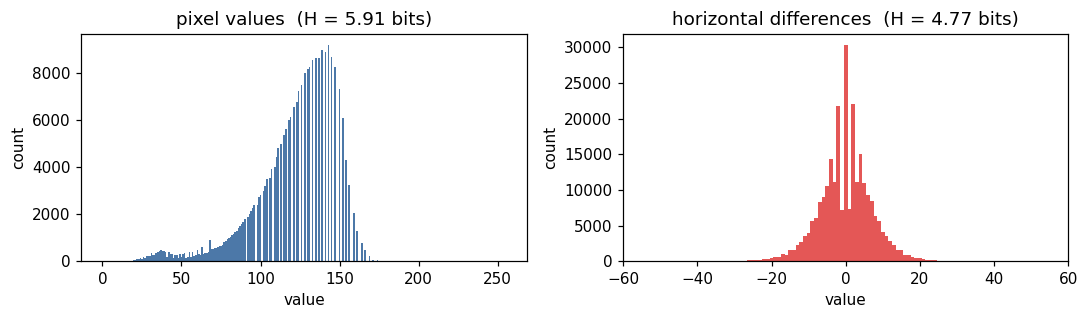

In [5]:
img = images["desert"]
d = img[:, 1:].astype(np.int16) - img[:, :-1].astype(np.int16)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].bar(range(256), histogram(img), width=1.0, color="#4c78a8")
ax[0].set_title(f"pixel values  (H = {entropy_bits(histogram(img)):.2f} bits)")
ax[1].bar(range(-255, 256), np.bincount((d + 255).ravel(), minlength=511), width=1.0, color="#e45756")
ax[1].set_title(f"horizontal differences  (H = {diff_entropy(img):.2f} bits)")
ax[1].set_xlim(-60, 60)
for a in ax:
    a.set_xlabel("value"); a.set_ylabel("count")
plt.tight_layout(); plt.show()

**What we see.** Pixel values spread over many gray levels, so $H$ is high, but the differences between neighbours pile up around 0, so their entropy is lower on the smooth images. That extra structure is why PNG (which predicts pixels from neighbours before coding) can beat the single-pixel entropy $H$. Huffman and LZW, as we implement them, work on the raw pixel values, so $H$ is the natural yardstick for them. The texture mosaic gains almost nothing, so the benefit depends on the image.

## 4. Codes, average length and Shannon's first theorem

A **code** gives each symbol a **code word** (a string of bits). Two rules matter:

- **Prefix-free.** No code word is the start of another. Then a stream of bits can be cut into words with no separators and no guessing. (If $0$ and $01$ are both words, then "01..." is ambiguous.)
- **Average length.** If symbol $k$ has probability $P_k$ and a code word of length $l_k$, the average number of bits per symbol is (book Eq. 8-4)

$$L_{avg} = \sum_k P_k\, l_k$$

Word lengths cannot be chosen freely. A prefix-free binary code with lengths $l_k$ exists exactly when the **Kraft inequality** holds:

$$\sum_k 2^{-l_k} \le 1$$

**Shannon's first theorem** (noiseless coding theorem) connects the two: for one code word per symbol the best average length satisfies $H \le L_{avg} < H + 1$. The "+1" comes from word lengths being whole bits. Shannon's trick for getting closer is to code **blocks** of $n$ symbols at once. The cost per symbol then drops to within $1/n$ of $H$. The book notes the catch: for 256 gray values, blocks of 2 pixels already need $256^2 = 65{,}536$ code words, and blocks of 3 need 16,777,216. This is why one code word per symbol (Huffman) is the practical choice.

In [6]:
def kraft_sum(lengths):
    return sum(2.0 ** -l for l in lengths)

def is_prefix_free(words):
    return not any(a != b and b.startswith(a) for a in words for b in words)

print("Kraft sum of the book's code (1,2,3,3):", kraft_sum([2, 1, 3, 3]))
print("Kraft sum of lengths (1,1,2):", kraft_sum([1, 1, 2]), " -> more than 1, no prefix-free code exists")
print("prefix-free {01, 1, 000, 001}:", is_prefix_free(["01", "1", "000", "001"]))
print("prefix-free {0, 01, 11}      :", is_prefix_free(["0", "01", "11"]))

Kraft sum of the book's code (1,2,3,3): 1.0
Kraft sum of lengths (1,1,2): 1.25  -> more than 1, no prefix-free code exists
prefix-free {01, 1, 000, 001}: True
prefix-free {0, 01, 11}      : False


In [7]:
# Shannon's block idea on a skewed two-symbol source: P = (0.9, 0.1).
# For each block we use a code word of length ceil(-log2 P(block)); these lengths always satisfy Kraft.
probs = [0.9, 0.1]
H = entropy_bits([9, 1])
out = []
for n in range(1, 9):
    block_p = np.array([np.prod(c) for c in product(probs, repeat=n)])
    lengths = np.ceil(-np.log2(block_p))
    out.append({"block size n": n, "code words": 2 ** n,
                "bits per symbol": round(float((block_p * lengths).sum() / n), 3),
                "H": round(H, 3), "H + 1/n": round(H + 1 / n, 3)})
pd.DataFrame(out).set_index("block size n")

,code words,bits per symbol,H,H + 1/n
block size n,,,,
1,2,1.300,0.469,1.469
2,4,0.800,0.469,0.969
3,8,0.633,0.469,0.802
4,16,0.551,0.469,0.719
5,32,0.516,0.469,0.669
6,64,0.545,0.469,0.636
7,128,0.586,0.469,0.612
8,256,0.550,0.469,0.594


The cost per symbol always stays between $H = 0.469$ and $H + 1/n$, so the guarantee tightens as $n$ grows. The exact value jumps around a little because code lengths are rounded up to whole bits. Meanwhile the number of code words doubles with every step. Coding single symbols as well as possible is what Huffman solved.

## 5. Simple methods that came before, and why they are not enough

**Fixed-length codes** (such as 8 bits per pixel) are simple but ignore probabilities: they have coding redundancy whenever the histogram is not flat (Sections 1 and 3).

**Run-length coding (RLE)** stores a pixel value and how many times it repeats. It removes spatial redundancy when long runs exist. The book's example, an image whose rows are each one constant value, compresses 128:1. We count 16 bits per run (8 for the value, 8 for the length), as the book does.

**Shannon–Fano coding** (Shannon 1948, Fano 1949) is a variable-length code built **top-down**: sort the symbols by probability, split the list into two groups with nearly equal total probability, give one group the digit 0 and the other 1, and repeat inside each group. It is good, but the splits are decided one at a time, so it is **not always optimal**. Huffman's 1952 paper fixed this by building the code **bottom-up**.

In [8]:
def rle_ratio(img, bits_per_run=16):
    runs = sum(1 + int(np.count_nonzero(row[1:] != row[:-1])) for row in img)
    return img.size * 8 / (runs * bits_per_run)

rng = np.random.default_rng(0)
test = dict(images)
test["book example: constant rows"] = np.repeat(rng.integers(0, 256, (256, 1)), 256, axis=1).astype(np.uint8)
test["vertical stripes (8 px)"] = np.tile((((np.arange(256) // 8) % 2) * 200 + 28).astype(np.uint8), (256, 1))
test["random noise"] = rng.integers(0, 256, (256, 256), dtype=np.uint8)

pd.DataFrame({"RLE compression ratio": {k: round(rle_ratio(v), 2) for k, v in test.items()}})

,RLE compression ratio
moon,0.53
desert,0.57
mandrill,0.52
texture mosaic,0.52
book example: constant rows,128.00
vertical stripes (8 px),4.00
random noise,0.50


RLE is spectacular on images made of runs, but on natural photos almost every pixel starts a new run, so each pixel costs 16 bits instead of 8 and the file **grows**. A general-purpose method must not depend on runs.

Next we compare Shannon–Fano with the optimum on a small example. For the optimum we use the fact that Huffman's bottom-up merging gives the minimum average length, and that average length equals the sum of all the merged weights. (The real Huffman encoder is the Huffman team's part; this is only a three-line check.)

In [9]:
def shannon_fano_lengths(p):
    # p must be sorted in decreasing order; returns the code length of each symbol
    lengths = [0] * len(p)
    def split(lo, hi):
        if hi - lo <= 1:
            return
        total = sum(p[lo:hi])
        acc, best = 0.0, None
        for i in range(lo, hi - 1):
            acc += p[i]
            gap = abs(2 * acc - total)          # how unequal are the two groups?
            if best is None or gap < best[0]:
                best = (gap, i + 1)
        for i in range(lo, hi):
            lengths[i] += 1                      # one more digit for everybody in this group
        split(lo, best[1]); split(best[1], hi)
    split(0, len(p))
    return lengths

def optimal_average_length(p):
    w, total = sorted(p), 0.0
    while len(w) > 1:                            # merge the two smallest, as in Huffman's paper
        merged = w[0] + w[1]
        total += merged
        w = sorted(w[2:] + [merged])
    return total

p = [0.35, 0.17, 0.17, 0.16, 0.15]
sf = shannon_fano_lengths(p)
print("entropy H               :", round(entropy_bits([35, 17, 17, 16, 15]), 4))
print("Shannon-Fano lengths    :", sf, "-> L_avg =", round(sum(a * b for a, b in zip(p, sf)), 4))
print("optimal (bottom-up) L_avg:", round(optimal_average_length(p), 4))

entropy H               : 2.2328
Shannon-Fano lengths    : [2, 2, 2, 3, 3] -> L_avg = 2.31
optimal (bottom-up) L_avg: 2.3


Shannon–Fano loses a little (2.31 against 2.30 bits). Small, but it shows that a top-down method cannot be trusted to be optimal. Huffman proved that bottom-up merging always is.

## 6. How this leads to Huffman and LZW

In the book's model a lossless compressor has two steps: a **mapper** (a reversible rearrangement of the data, such as run lengths or differences) followed by a **symbol coder** (variable-length code words). A third step, the **quantizer**, throws information away, so lossless methods leave it out.

| | Huffman (1952) | LZW (1984) |
|---|---|---|
| Redundancy attacked | coding redundancy | repeated patterns of symbols |
| Needs probabilities in advance? | yes (needs the histogram first) | no (learns a table while reading) |
| Core idea | short words for common symbols, built bottom-up, provably optimal for one word per symbol | table of strings already seen; output the index of the longest known string |
| Limit it runs into | cannot go below $H$ and whole-bit lengths; ignores neighbours | table size, startup cost, no probabilities |

The Huffman part of the project shows how to reach the entropy bound as closely as one code word per symbol allows. The LZW part shows a way to exploit repeated patterns without knowing any probabilities. Both are measured against the entropy $H$ and against PNG.